In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")

y_train = pd.read_csv("y_train.csv")["class"]
y_test = pd.read_csv("y_test.csv")["class"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])

print("\nTraining target distribution:")
print(y_train.value_counts())


Training records: 160
Testing records: 40
Number of features: 25

Training target distribution:
class
1    102
0     58
Name: count, dtype: int64


In [3]:

categorical_features = X_train.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


In [4]:

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=4,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

decision_tree_model.fit(X_train, y_train)

dt_pred = decision_tree_model.predict(X_test)
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree training completed.")


Decision Tree training completed.


In [5]:

# Fit preprocessing using training data only.
nb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            categorical_features
        )
    ],
    remainder="drop",
    sparse_threshold=0
)

X_train_nb = nb_preprocessor.fit_transform(X_train)
X_test_nb = nb_preprocessor.transform(X_test)

naive_bayes_model = GaussianNB()

naive_bayes_model.fit(X_train_nb, y_train)

nb_pred = naive_bayes_model.predict(X_test_nb)
nb_prob = naive_bayes_model.predict_proba(X_test_nb)[:, 1]

print("Naive Bayes training completed.")


Naive Bayes training completed.


In [6]:

def evaluate_model(model_name, y_true, y_pred, y_prob):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

results = pd.DataFrame([
    evaluate_model(
        "Decision Tree", y_test, dt_pred, dt_prob
    ),
    evaluate_model(
        "Naive Bayes", y_test, nb_pred, nb_prob
    )
])

display(results.round(4))

results.to_csv("tree_naive_bayes_results.csv", index=False)
print("Evaluation results saved.")


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.975,1.000,0.9615,0.9804,0.9780
1,Naive Bayes,0.975,0.963,1.0000,0.9811,0.9643


Evaluation results saved.


In [7]:

print("DECISION TREE CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    dt_pred,
    labels=[0, 1],
    target_names=["Non-CKD", "CKD"],
    zero_division=0
))

print("\nNAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    nb_pred,
    labels=[0, 1],
    target_names=["Non-CKD", "CKD"],
    zero_division=0
))


DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Non-CKD       0.93      1.00      0.97        14
         CKD       1.00      0.96      0.98        26

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40


NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Non-CKD       1.00      0.93      0.96        14
         CKD       0.96      1.00      0.98        26

    accuracy                           0.97        40
   macro avg       0.98      0.96      0.97        40
weighted avg       0.98      0.97      0.97        40



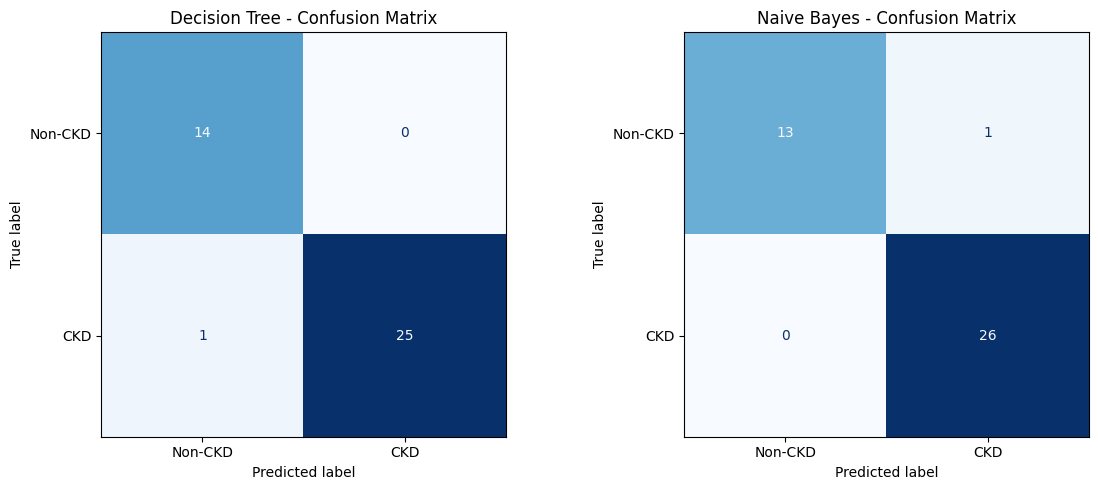

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model_name, predictions in [
    (axes[0], "Decision Tree", dt_pred),
    (axes[1], "Naive Bayes", nb_pred)
]:
    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-CKD", "CKD"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} - Confusion Matrix")

plt.tight_layout()
plt.savefig(
    "tree_naive_bayes_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


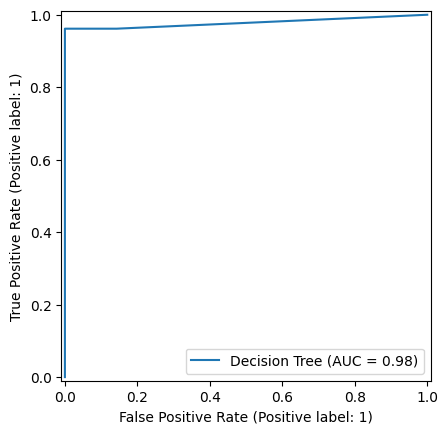

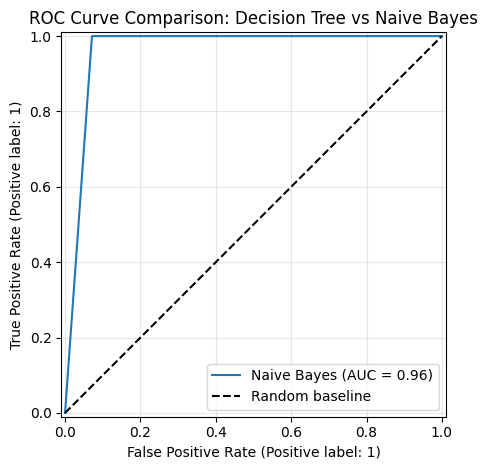

In [9]:

RocCurveDisplay.from_predictions(
    y_test,
    dt_prob,
    name="Decision Tree"
)

RocCurveDisplay.from_predictions(
    y_test,
    nb_prob,
    name="Naive Bayes"
)

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random baseline"
)

plt.title("ROC Curve Comparison: Decision Tree vs Naive Bayes")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "tree_naive_bayes_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,1.000,1.000,1.0000,1.0000,1.0000
1,Decision Tree,0.975,1.000,0.9615,0.9804,0.9780
2,Naive Bayes,0.975,0.963,1.0000,0.9811,0.9643


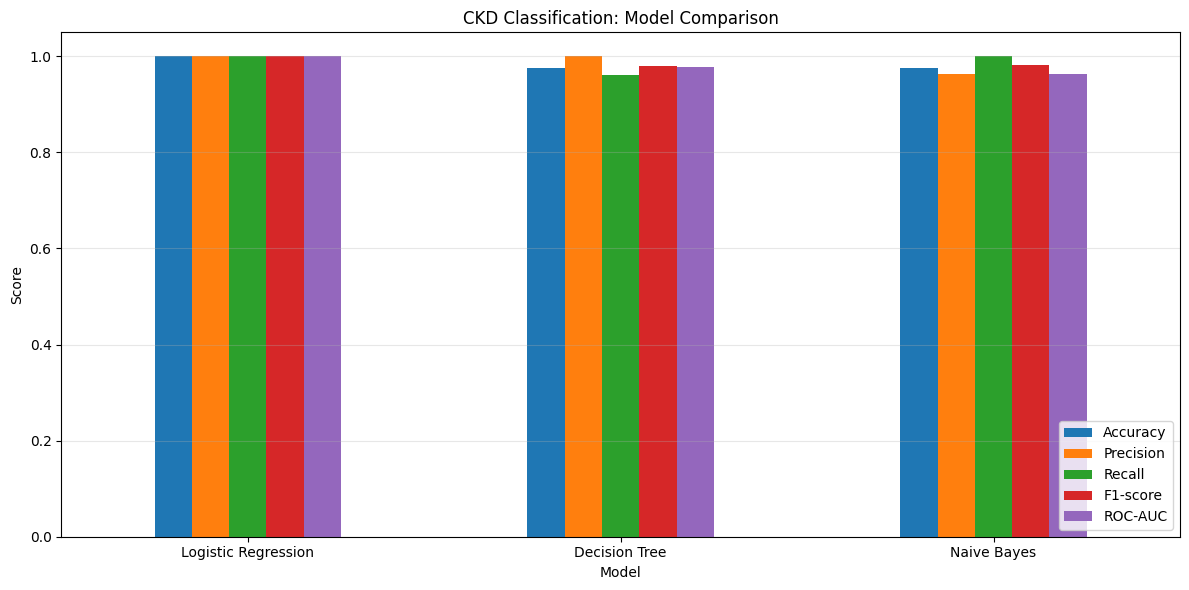

In [10]:

logistic_results = pd.read_csv("logistic_results.csv")

all_results = pd.concat(
    [logistic_results, results],
    ignore_index=True
)

display(all_results.round(4))

all_results.to_csv(
    "ckd_all_models_comparison.csv",
    index=False
)

metrics = [
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC"
]

all_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("CKD Classification: Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(
    "ckd_all_models_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [11]:

from sklearn.ensemble import RandomForestClassifier


In [12]:

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

random_forest_model.fit(X_train, y_train)

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest training completed.")


Random Forest training completed.


In [13]:

rf_results = pd.DataFrame([
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred,
        rf_prob
    )
])

display(rf_results.round(4))

rf_results.to_csv("random_forest_results.csv", index=False)

print(classification_report(
    y_test,
    rf_pred,
    labels=[0, 1],
    target_names=["Non-CKD", "CKD"],
    zero_division=0
))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.975,1.0,0.9615,0.9804,1.0


              precision    recall  f1-score   support

     Non-CKD       0.93      1.00      0.97        14
         CKD       1.00      0.96      0.98        26

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40



In [14]:

from sklearn.svm import SVC


In [15]:

svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)
svm_prob = svm_model.predict_proba(X_test)[:, 1]

print("SVM training completed.")


SVM training completed.


In [16]:

svm_results = pd.DataFrame([
    evaluate_model(
        "SVM",
        y_test,
        svm_pred,
        svm_prob
    )
])

display(svm_results.round(4))

svm_results.to_csv("svm_results.csv", index=False)

print(classification_report(
    y_test,
    svm_pred,
    labels=[0, 1],
    target_names=["Non-CKD", "CKD"],
    zero_division=0
))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SVM,1.0,1.0,1.0,1.0,1.0


              precision    recall  f1-score   support

     Non-CKD       1.00      1.00      1.00        14
         CKD       1.00      1.00      1.00        26

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,1.000,1.000,1.0000,1.0000,1.0000
4,SVM,1.000,1.000,1.0000,1.0000,1.0000
1,Decision Tree,0.975,1.000,0.9615,0.9804,0.9780
2,Naive Bayes,0.975,0.963,1.0000,0.9811,0.9643
3,Random Forest,0.975,1.000,0.9615,0.9804,1.0000


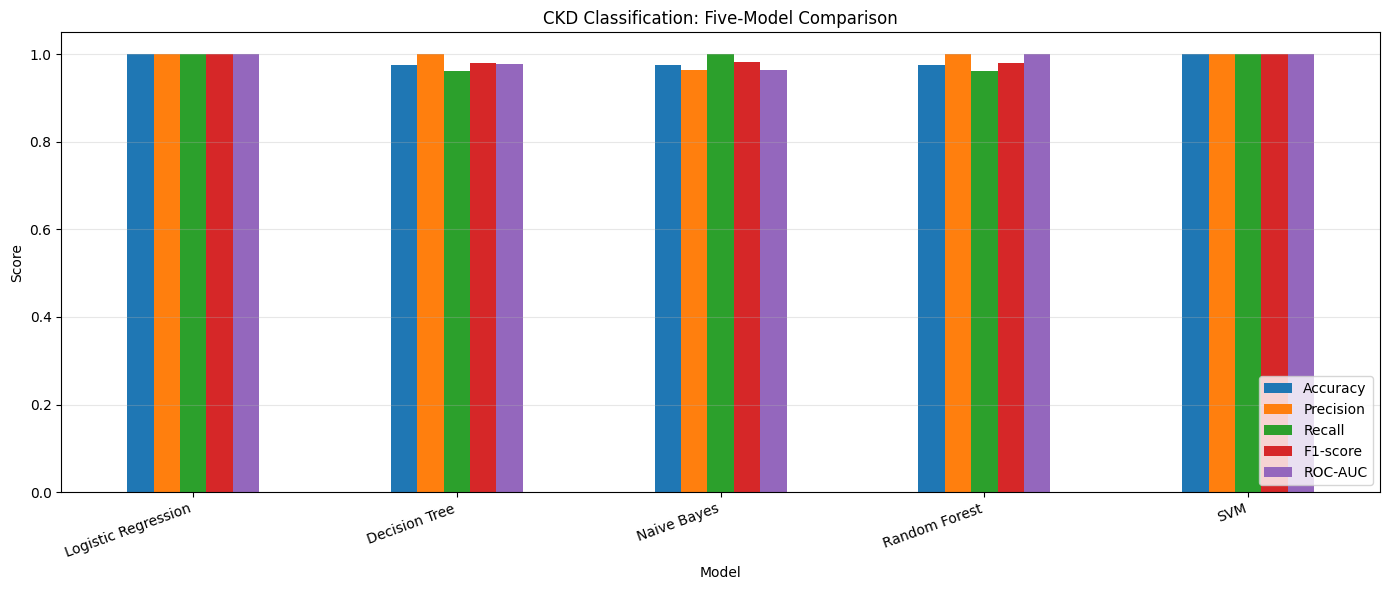

In [17]:

all_results = pd.concat([
    pd.read_csv("logistic_results.csv"),
    results,
    rf_results,
    svm_results
], ignore_index=True)

display(
    all_results.sort_values(
        by="Accuracy",
        ascending=False
    ).round(4)
)

all_results.to_csv(
    "ckd_five_models_comparison.csv",
    index=False
)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

all_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 6),
    ylim=(0, 1.05)
)

plt.title("CKD Classification: Five-Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(
    "ckd_five_models_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
